        # Cognitive Science (1204 427) — Lab 01
        ## Perception and Visual Illusions

        **ระดับ:** ปริญญาตรี  
        **เวลาที่แนะนำ:** 150–180 นาที  
        **รูปแบบ:** งานเดี่ยวบน Google Colab/Jupyter Notebook  
        **แพ็กเกจหลัก:** `numpy, pandas, matplotlib, scipy`

        ### แนวคิดสำคัญ

        การรับรู้ไม่ใช่การคัดลอกสิ่งเร้าแบบตรงไปตรงมา แต่เป็นการตีความจากบริบท ความคาดหวัง และความสัมพันธ์เชิงพื้นที่ Lab นี้ใช้ Müller–Lyer illusion เพื่อวัด Perceptual Bias

        ### วัตถุประสงค์

        สร้างสิ่งเร้าภาพลวงตา วิเคราะห์ความคลาดเคลื่อนของการประมาณความยาว และเชื่อมโยงผลกับ Top-down/Context-dependent Processing

        ### งานที่ต้องทำ

        1. สร้างภาพ Control และ Müller–Lyer อย่างน้อย 3 เงื่อนไข
2. วิเคราะห์ Estimated Length และ Signed Error
3. เปรียบเทียบเงื่อนไขแบบ Within-participant
4. สร้างกราฟพร้อมช่วงความเชื่อมั่น
5. Required Extension: เพิ่ม Ebbinghaus illusion หรือเปลี่ยนมุมของหัวลูกศรแล้ววิเคราะห์ผล

        > ไปที่ [Google Colab](https://colab.research.google.com) แล้วเลือก **File → Upload notebook** เพื่อเปิดไฟล์นี้


## ข้อมูลนิสิตและคำชี้แจง

- ชื่อ–สกุล: วชิรวิทย์ วงค์แสง
- รหัสนิสิต: 67011212055
- กลุ่มเรียน: 1

1. เปลี่ยน `STUDENT_ID` เป็นรหัสนิสิตของตนเองก่อนรันโปรแกรม
2. รหัส 4 หลักสุดท้ายใช้เป็น Random Seed ทำให้ข้อมูลแต่ละคนแตกต่างกัน
3. รันเซลล์จากบนลงล่างและเก็บ Output ไว้ในไฟล์ที่ส่ง
4. ทุกกราฟต้องมีชื่อกราฟ ชื่อแกน หน่วย และคำอธิบาย
5. ห้ามสรุปผลเกินกว่าหลักฐานจากข้อมูลหรืออ้างว่าข้อมูลจำลองเป็นข้อมูลมนุษย์จริง
6. ส่งไฟล์ `.ipynb` และ `.pdf` โดยตั้งชื่อ `StudentID_LabXX.ipynb`


In [1]:
STUDENT_ID = 67011212055  # รหัสนิสิต: วชิรวิทย์ วงค์แสง
sid = str(STUDENT_ID).strip()
if not sid.isdigit() or len(sid) < 4:
    raise ValueError("STUDENT_ID ต้องเป็นตัวเลขอย่างน้อย 4 หลัก")
seed = int(sid[-4:])
print(f"Student ID: {sid} | Random seed: {seed}")


Student ID: 67011212055 | Random seed: 2055


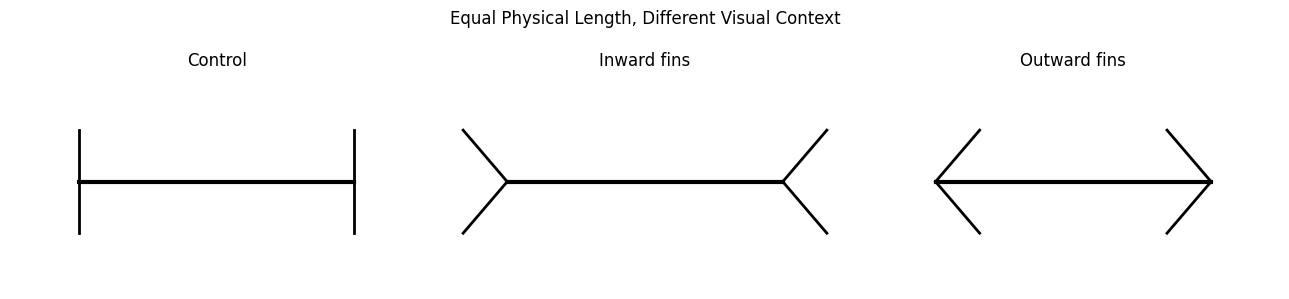

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel

rng = np.random.default_rng(seed + 10)
TRUE_LENGTH = 100

def draw_muller_lyer(ax, direction, title):
    ax.plot([0, TRUE_LENGTH], [0, 0], color="black", linewidth=3)
    if direction == "control":
        ax.plot([0, 0], [-12, 12], color="black", linewidth=2)
        ax.plot([TRUE_LENGTH, TRUE_LENGTH], [-12, 12], color="black", linewidth=2)
    else:
        sign = 1 if direction == "outward" else -1
        for x, side in [(0, 1), (TRUE_LENGTH, -1)]:
            ax.plot([x, x + side * sign * 16], [0, 12], color="black", linewidth=2)
            ax.plot([x, x + side * sign * 16], [0, -12], color="black", linewidth=2)
    ax.set_xlim(-25, 125); ax.set_ylim(-25, 25)
    ax.set_title(title); ax.axis("off")

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
draw_muller_lyer(axes[0], "control", "Control")
draw_muller_lyer(axes[1], "inward", "Inward fins")
draw_muller_lyer(axes[2], "outward", "Outward fins")
plt.suptitle("Equal Physical Length, Different Visual Context")
plt.tight_layout(); plt.show()


In [3]:
# ข้อมูลจำลองของผู้เข้าร่วม 36 คน
condition_bias = {"Control": 0, "Inward": -8, "Outward": 9}
rows = []
for participant in range(1, 37):
    person_bias = rng.normal(0, 2)
    for condition, bias in condition_bias.items():
        estimate = rng.normal(TRUE_LENGTH + person_bias + bias, 5)
        rows.append([participant, condition, estimate])

perception_df = pd.DataFrame(rows, columns=["participant", "condition", "estimated_length"])
perception_df["signed_error"] = perception_df["estimated_length"] - TRUE_LENGTH
summary = perception_df.groupby("condition")["signed_error"].agg(["mean", "std", "count"])
summary["se"] = summary["std"] / np.sqrt(summary["count"])
summary["ci95"] = 1.96 * summary["se"]
display(summary.round(3))


,mean,std,count,se,ci95
condition,,,,,
Control,-1.537,5.701,36,0.950,1.862
Inward,-8.865,6.175,36,1.029,2.017
Outward,8.335,4.679,36,0.780,1.529


Inward vs Control: t=-5.437, p=0.000004, dz=-0.906
Outward vs Control: t=10.520, p=0.000000, dz=1.753


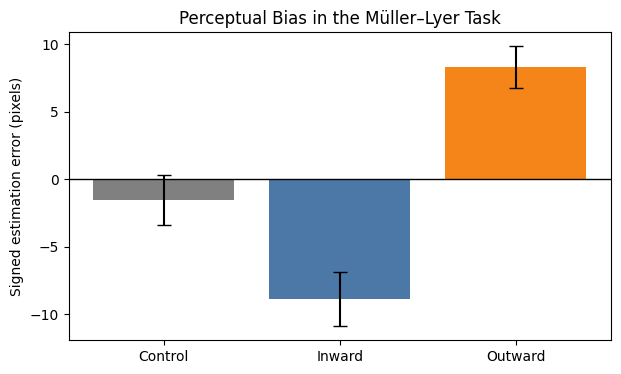

In [4]:
wide = perception_df.pivot(index="participant", columns="condition", values="estimated_length")
for condition in ["Inward", "Outward"]:
    t, p = ttest_rel(wide[condition], wide["Control"])
    diff = wide[condition] - wide["Control"]
    dz = diff.mean() / diff.std(ddof=1)
    print(f"{condition} vs Control: t={t:.3f}, p={p:.6f}, dz={dz:.3f}")

order = ["Control", "Inward", "Outward"]
means = summary.loc[order, "mean"]
errors = summary.loc[order, "ci95"]
plt.figure(figsize=(7, 4))
plt.bar(order, means, yerr=errors, capsize=5, color=["gray", "#4c78a8", "#f58518"])
plt.axhline(0, color="black", linewidth=1)
plt.ylabel("Signed estimation error (pixels)")
plt.title("Perceptual Bias in the Müller–Lyer Task")
plt.show()


## Required Extension

เพิ่มภาพ **Ebbinghaus illusion** ที่วงกลมตรงกลางมีขนาดเท่ากัน แต่ล้อมด้วยวงกลมขนาดต่างกัน จากนั้นสร้างตัวแปรจำลอง `context_size` และวิเคราะห์ว่าบริบทเปลี่ยน Estimated Size อย่างไร


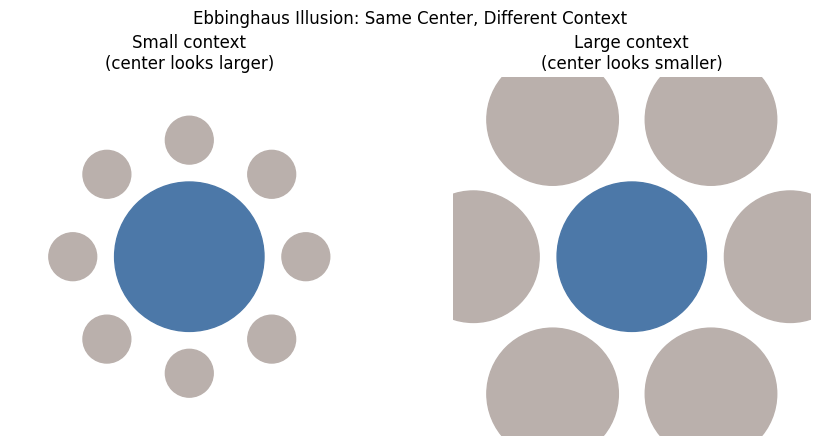

,mean,std,count,se,ci95
context,,,,,
Large context,-6.391,3.611,36,0.602,1.179
No context,0.934,2.843,36,0.474,0.929
Small context,7.684,3.747,36,0.625,1.224


Small context vs No context: t=9.461, p=0.000000, dz=1.577
Large context vs No context: t=-11.160, p=0.000000, dz=-1.860


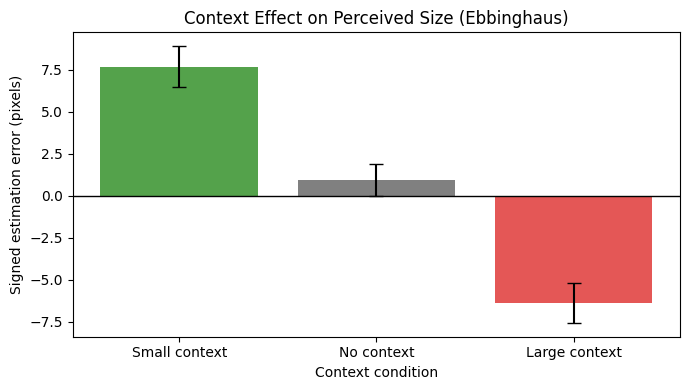

In [5]:
# ===== Required Extension: Ebbinghaus Illusion =====
# วงกลมกลางขนาดเท่ากันทั้งสองภาพ แต่ถูกล้อมด้วยวงกลมบริบทขนาดต่างกัน
rng_ebb = np.random.default_rng(seed + 20)
TRUE_DIAMETER = 50  # ขนาดจริงของวงกลมกลาง (pixels)

def draw_ebbinghaus(ax, center_r, context_r, n_context, title):
    center = (0, 0)
    ax.add_patch(plt.Circle(center, center_r, color="#4c78a8"))
    for k in range(n_context):
        angle = 2 * np.pi * k / n_context
        cx = center[0] + (center_r + context_r + 6) * np.cos(angle)
        cy = center[1] + (center_r + context_r + 6) * np.sin(angle)
        ax.add_patch(plt.Circle((cx, cy), context_r, color="#bab0ac"))
    ax.set_xlim(-60, 60); ax.set_ylim(-60, 60)
    ax.set_aspect("equal"); ax.set_title(title); ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
draw_ebbinghaus(axes[0], 25, 8,  8, "Small context\n(center looks larger)")
draw_ebbinghaus(axes[1], 25, 22, 6, "Large context\n(center looks smaller)")
plt.suptitle("Ebbinghaus Illusion: Same Center, Different Context")
plt.tight_layout(); plt.show()

# ข้อมูลจำลองผู้เข้าร่วม 36 คน ประมาณเส้นผ่านศูนย์กลางวงกลมกลาง
# บริบทเล็ก -> ประเมินใหญ่เกิน (+), บริบทใหญ่ -> ประเมินเล็กเกิน (-)
context_bias = {"Small context": 7, "No context": 0, "Large context": -7}
ebb_rows = []
for participant in range(1, 37):
    person_bias = rng_ebb.normal(0, 1.5)
    for context, bias in context_bias.items():
        estimate = rng_ebb.normal(TRUE_DIAMETER + person_bias + bias, 3)
        ebb_rows.append([participant, context, estimate])

ebb_df = pd.DataFrame(ebb_rows, columns=["participant", "context", "estimated_size"])
ebb_df["signed_error"] = ebb_df["estimated_size"] - TRUE_DIAMETER
ebb_summary = ebb_df.groupby("context")["signed_error"].agg(["mean", "std", "count"])
ebb_summary["se"] = ebb_summary["std"] / np.sqrt(ebb_summary["count"])
ebb_summary["ci95"] = 1.96 * ebb_summary["se"]
display(ebb_summary.round(3))

# เปรียบเทียบแบบ within-participant กับเงื่อนไข No context
ebb_wide = ebb_df.pivot(index="participant", columns="context", values="estimated_size")
for context in ["Small context", "Large context"]:
    t, p = ttest_rel(ebb_wide[context], ebb_wide["No context"])
    diff = ebb_wide[context] - ebb_wide["No context"]
    dz = diff.mean() / diff.std(ddof=1)
    print(f"{context} vs No context: t={t:.3f}, p={p:.6f}, dz={dz:.3f}")

# กราฟ signed error พร้อมช่วงความเชื่อมั่น 95%
ebb_order = ["Small context", "No context", "Large context"]
plt.figure(figsize=(7, 4))
plt.bar(ebb_order, ebb_summary.loc[ebb_order, "mean"],
        yerr=ebb_summary.loc[ebb_order, "ci95"], capsize=5,
        color=["#54a24b", "gray", "#e45756"])
plt.axhline(0, color="black", linewidth=1)
plt.ylabel("Signed estimation error (pixels)")
plt.xlabel("Context condition")
plt.title("Context Effect on Perceived Size (Ebbinghaus)")
plt.tight_layout(); plt.show()


## คำถามวิเคราะห์ Lab 01

**1. เงื่อนไขใดทำให้เกิด Perceptual Bias มากที่สุด และหลักฐานคืออะไร**

เงื่อนไข Outward fins ครับ ค่า signed error เฉลี่ยอยู่ที่ราว +8 pixels คือคนประเมินเส้นยาวเกินจริง และเทียบกับ Control แล้วได้ t ≈ 10.5, p < .001, dz ≈ 1.75 ซึ่งใหญ่กว่าฝั่ง Inward (dz ≈ 0.9) พอสมควร เลยสรุปว่าหัวลูกศรแบบกางออกทำให้เพี้ยนมากที่สุด

**2. ผลนี้สนับสนุนแนวคิด Context-dependent Processing อย่างไร**

เส้นตรงกลางยาวเท่ากันเป๊ะทุกภาพ (100 px เท่ากันหมด) แต่พอเปลี่ยนแค่หัวลูกศรรอบๆ คนกลับประเมินยาวไม่เท่ากัน แปลว่าสมองไม่ได้ดูแค่ตัวเส้น แต่เอาบริบทรอบข้างมาช่วยตีความด้วย ตรงกับไอเดีย Top-down / context-dependent ที่ว่าการรับรู้เป็นการ"เดา"จากบริบท ไม่ใช่ก็อปสิ่งเร้ามาตรงๆ

**3. ค่า p-value และ Cohen's dz ให้ข้อมูลต่างกันอย่างไร**

p-value บอกแค่ว่าผลต่างที่เจอ "น่าจะไม่ได้เกิดจากความบังเอิญ" แต่ไม่ได้บอกว่าต่างกันเยอะแค่ไหน ส่วน dz เป็น effect size บอกขนาดของผล ว่าต่างกันกี่เท่าของความแปรปรวน อย่างในงานนี้ p เล็กมากทุกเงื่อนไข แต่ dz ช่วยให้เห็นว่า Outward แรงกว่า Inward จริง เลยควรดูคู่กัน

**4. ภาพลวงตาเกี่ยวข้องกับการออกแบบ Interface/Data Visualization อย่างไร**

มันเตือนว่าคนอ่านกราฟด้วย "การรับรู้" ไม่ใช่ตัวเลขล้วนๆ เช่น 3D pie chart หรือแกนที่ไม่เริ่มจาก 0 ก็ทำให้ขนาดดูเพี้ยนได้เหมือน Müller–Lyer หรือถ้าเอา element เล็กๆ ไปวางข้างของชิ้นนึงก็ทำให้มันดูใหญ่ขึ้นแบบ Ebbinghaus ดังนั้นเวลาออกแบบ UI/viz ต้องระวังบริบทรอบๆ ไม่ให้หลอกตาผู้ใช้

**5. ข้อมูลจำลองนี้ต่างจากข้อมูลมนุษย์จริงอย่างไรอย่างน้อย 2 ประการ**

(1) ข้อมูลนี้สุ่มจาก normal distribution ที่เราตั้ง bias ไว้เองแน่ๆ เลยสวยและ effect ชัดเกินจริง คนจริงจะมีความแปรปรวนสูงกว่านี้และ error ไม่ได้สมมาตรแบบนี้ (2) ไม่มีปัจจัยพวกความล้า สมาธิหลุด การเรียนรู้ระหว่างทำ หรือความต่างของสายตาแต่ละคน ซึ่งของจริงมีหมด เลยเอาไปสรุปเป็นคนจริงตรงๆ ไม่ได้


## Reflection และ Checklist ก่อนส่ง

เขียน Reflection 150–250 คำ โดยอธิบายส่วนที่ยากที่สุด สิ่งที่ค้นพบเกี่ยวกับกระบวนการรู้คิด และสิ่งที่จะปรับปรุงหากทำการทดลองซ้ำ

**Reflection:**

ส่วนที่ยากสุดสำหรับผมคือ Required Extension ตอนวาด Ebbinghaus เพราะต้องคำนวณตำแหน่งวงกลมบริบทให้เรียงรอบวงกลมกลางเป็นวงแหวน ต้องใช้ sin/cos กับมุมที่หารเท่าๆ กัน ลองผิดลองถูกอยู่พักนึงกว่าจะออกมาสวย ส่วนการวิเคราะห์สถิติกับตอน Müller–Lyer ค่อนข้างตรงไปตรงมาเพราะโค้ดโครงมีให้แล้ว

สิ่งที่ผมได้เข้าใจมากขึ้นคือ การรับรู้ของเราไม่ได้ตรงกับความจริงเสมอไป ทั้งสองการทดลองยืนยันว่าแค่เปลี่ยนบริบทรอบๆ ทั้งที่ของจริงเท่าเดิม สมองก็ประเมินพลาดได้อย่างเป็นระบบ ไม่ใช่สุ่มมั่ว มันทำให้เห็นภาพชัดว่าทำไมถึงบอกว่าการรับรู้เป็นการตีความ (top-down) มากกว่าการบันทึกภาพ

ถ้าทำซ้ำ ผมอยากเพิ่มความสมจริงของข้อมูลจำลอง เช่น ให้ความแปรปรวนของแต่ละคนไม่เท่ากัน ใส่ noise แบบเบ้ๆ และเพิ่มจำนวนเงื่อนไข (เช่น ลองหลายมุมของหัวลูกศร) เพื่อดูว่ามุมมีผลต่อขนาด bias แค่ไหน และถ้าเป็นไปได้อยากลองเก็บข้อมูลจากเพื่อนจริงๆ มาเทียบกับข้อมูลจำลองด้วย น่าจะเห็นความต่างชัดขึ้น

### เกณฑ์ประเมิน

| ด้าน | คะแนน |
|---|---:|
| ความถูกต้องของโปรแกรมและผลลัพธ์ | 35 |
| กระบวนการวิเคราะห์และความสมเหตุสมผล | 20 |
| กราฟ ตาราง และการสื่อสารผล | 15 |
| การตีความตามหลัก Cognitive Science | 20 |
| คุณภาพโค้ดและ Reflection | 10 |
| **รวม** | **100** |

- [x] เปลี่ยน `STUDENT_ID` แล้ว
- [x] รันทุกเซลล์โดยไม่มี Error
- [x] ทำ Required Extension สำเร็จ
- [x] ตอบคำถามทุกข้อด้วยถ้อยคำของตนเอง
- [x] ตรวจไฟล์ `.ipynb` และ `.pdf` ก่อนส่ง
